# Tarea 2 · Deep Learning (CIT3360) — Ítem 1: YOLO entrenado desde cero

> **Variante 80/10/10.** Copia de `../02_yolo_desde_cero.ipynb` que entrena y evalúa con la partición 80/10/10 de esta carpeta (train 2400, val 301 y test 301 imágenes; huella `84ea7ae5b688`). Solo cambian las rutas, la huella y los textos que dependen de la partición: el diseño, los hiperparámetros y las decisiones del grupo son los del original, salvo el NMS de la evaluación: IoU 0,5 en vez de 0,7 (`IOU_NMS`, cambio del 9 de noviembre de 2026; el entrenamiento no se repitió). Los pesos y registros van a `~/tarea2_runs_80_10_10/`.

Detector **YOLOv8** (Ultralytics) entrenado **desde cero** sobre FjordFish: la red se construye a partir de su archivo de arquitectura (`yolov8n.yaml`) con pesos inicializados aleatoriamente; no se usan pesos preentrenados (ni COCO ni ImageNet). Se entrena, valida y prueba con las mismas particiones que la CNN propia (`01_cnn_propia_desde_cero.ipynb`), generadas por `00_preparacion_dataset.ipynb`.

**Ítems de la rúbrica:** 1.1 (YOLO desde cero, secciones 3 a 6), 1.2 (mismas particiones, sección 2) y 1.3 (justificación, sección 12). La comparación con la CNN (1.4) está en `05_comparacion.ipynb`.

**Decisiones del grupo que aplica este cuaderno** (detalle en `PLAN_TAREA2.md` §4)
- Entrada de 640 px con *letterbox* (D3), igual que la CNN propia.
- El mismo aumento de datos que la CNN propia, **sin mosaico** (D5): escala, traslación, color (HSV) y volteo horizontal.
- Las 28 categorías de `data.yaml` (D6).

**Contenido**
0. Entorno · 1. Configuración · 2. Verificación de las particiones · 3. Arquitectura · 4. Entrenamiento · 5. Curvas de entrenamiento · 6. Evaluación en validación y test (Ultralytics) · 7. Eficiencia · 8. Resultados cualitativos · 9. Predicciones de validación y test · 10. Métricas con el evaluador común · 11. Resumen para la comparación · 12–13. Justificación y análisis (grupo)

> **Nota:** al iniciar el entrenamiento, Ultralytics descarga `yolo26n.pt` **solo para comprobar que la precisión mixta (AMP) funciona en la GPU**. Ese modelo no se usa para inicializar ni para entrenar el YOLO de este cuaderno.

## 0. Entorno

Requiere `ultralytics`, PyTorch con CUDA (ver `requirements.txt`) y `comun.py` en la misma carpeta que el cuaderno. En Windows, `torchvision` debe ser la versión con CUDA que corresponde a la versión instalada de PyTorch.

In [1]:
import json
import time
import random
import platform
from importlib.util import find_spec
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from PIL import Image
import ultralytics
from ultralytics import YOLO
from ultralytics.nn.tasks import DetectionModel
from ultralytics.utils.torch_utils import get_flops

from comun import cargar_particiones, verificar_huella, cargar_cajas_reales, evaluar_detecciones, CARPETA_RUNS

print("Python      :", platform.python_version())
print("PyTorch     :", torch.__version__, "| CUDA disponible:", torch.cuda.is_available())
print("Ultralytics :", ultralytics.__version__)
if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0))
# Con albumentations instalado, Ultralytics agrega aumentos (desenfoque, CLAHE, gris) que la CNN propia no tiene
assert find_spec("albumentations") is None, "Desinstalar albumentations para que YOLO y la CNN usen el mismo aumento (D5)"
DISPOSITIVO = 0 if torch.cuda.is_available() else "cpu"

Python      : 3.14.0
PyTorch     : 2.14.0+cu130 | CUDA disponible: True
Ultralytics : 8.4.192
GPU         : NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
# Estilo de los gráficos: colores categóricos en orden fijo (azul, naranja, aqua) y ejes discretos
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False, "figure.dpi": 100,
})

## 1. Configuración del experimento

Todos los parámetros del experimento están en esta celda; el resto del cuaderno no tiene valores fijos. Los valores de partida son los de Ultralytics por defecto, salvo:

- `epochs` = 300 y `patience` = 50 (por defecto 100 y 100).
- `optimizer` = `"SGD"` (por defecto `"auto"`). Con `"auto"`, Ultralytics ignora `lr0` y `momentum` y elige según el número de iteraciones: con este dataset (< 10 000 iteraciones) usaría AdamW con `lr0 = 0.002·5/(4 + nc) ≈ 3·10⁻⁴`.
- `seed` = 42 (por defecto 0).
- `mosaic` = 0 (por defecto 1): el grupo decidió que ni YOLO ni la CNN propia usen mosaico (D5). El resto del aumento queda con los valores por defecto, y la CNN propia implementa exactamente el mismo: escala aleatoria entre 0,5× y 1,5×, traslación de hasta ±10 %, cambios de tono, saturación y brillo (HSV) y volteo horizontal con probabilidad 0,5.

Referencia medida en una RTX 4060 Laptop con `yolov8n`, `imgsz=640` y mosaico: ~17 s por época (la primera ~1,5 min por la puesta en marcha), es decir, ~1,5 h para 300 épocas.

| Parámetro | Qué controla |
|---|---|
| `MODELO_YAML` | arquitectura y escala de la red (`yolov8n`, `yolov8s`, …) |
| `epochs`, `patience` | máximo de épocas; parada temprana si el mAP50-95 de validación no mejora en `patience` épocas |
| `imgsz`, `batch` | lado de la imagen de entrada (px) y tamaño de lote (los gradientes se acumulan hasta un lote nominal de 64) |
| `optimizer`, `lr0`, `lrf`, `momentum`, `warmup_epochs`, `cos_lr` | optimizador y programa de la tasa de aprendizaje (decae de `lr0` a `lr0·lrf`; lineal o coseno) |
| `weight_decay` | regularización L2 |
| `cls_pw` | ponderación de clases inversa a su frecuencia (0 = desactivada) |
| `hsv_*`, `degrees`, `translate`, `scale`, `shear`, `perspective`, `flipud`, `fliplr`, `mosaic`, `mixup`, `cutmix` | aumento de datos (magnitudes y probabilidades) |
| `N_IMAGENES_VELOCIDAD`, `N_EJEMPLOS` | imágenes para medir la velocidad y para los ejemplos cualitativos |
| `UMBRAL_CONFIANZA` | confianza mínima de las detecciones que se dibujan en los ejemplos y de la medición de velocidad (umbral común que fijó el grupo, D8) |

Con `PRUEBA_RAPIDA = True` se entrena 3 épocas con el 10 % de train, para comprobar que todo el cuaderno funciona antes del entrenamiento completo; sus salidas van a `pruebas/` para no pisar los resultados reales. Con `ENTRENAR = False` se omite el entrenamiento y se reutiliza el guardado (útil para volver a generar gráficos y tablas).

Los pesos y registros del entrenamiento se guardan en `~/tarea2_runs_80_10_10/` (`CARPETA_RUNS` de `comun.py`), fuera de OneDrive: la sincronización bloquea los archivos que se reescriben en cada época y detiene el entrenamiento. Las tablas y figuras van en `resultados/yolo_desde_cero/`, dentro del proyecto.

In [3]:
RAIZ = Path.cwd()
PRUEBA_RAPIDA = False     # True: 3 épocas con el 10 % de train para probar el flujo completo
ENTRENAR = False          # False: reutiliza el entrenamiento guardado en RUN_EXISTENTE

DATA_YAML = RAIZ / "datasets" / "fjordfish" / "fjordfish.yaml"
DIR_DATASET = DATA_YAML.parent
DIR_SPLITS = RAIZ / "splits"
DIR_BASE = RAIZ / "pruebas" if PRUEBA_RAPIDA else RAIZ        # las pruebas no pisan los resultados reales
DIR_RUNS = CARPETA_RUNS / ("pruebas" if PRUEBA_RAPIDA else "reales") / "yolo_desde_cero"   # pesos y registros, fuera de OneDrive
DIR_RESULTADOS = DIR_BASE / "resultados" / "yolo_desde_cero"   # tablas y figuras para la presentación
RUN_EXISTENTE = DIR_RUNS / "entrenamiento"

SEMILLA = 42
MODELO_YAML = "yolov8n.yaml"   # YOLOv8 escala n, construido desde su YAML (pesos aleatorios)

HIPERPARAMETROS = dict(
    epochs=300,
    patience=50,
    imgsz=640,
    batch=16,
    optimizer="SGD",
    lr0=0.01,
    lrf=0.01,
    momentum=0.937,
    weight_decay=5e-4,
    warmup_epochs=3.0,
    cos_lr=False,
    close_mosaic=0,        # sin mosaico (D5): no hay nada que desactivar al final
    cls_pw=0.0,
)
AUMENTO_DATOS = dict(      # el mismo conjunto que implementa la CNN propia (D5)
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    degrees=0.0, translate=0.1, scale=0.5, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.5,
    mosaic=0.0, mixup=0.0, cutmix=0.0,
)
UMBRAL_CONFIANZA = 0.25   # D8: umbral común que fijó el grupo con validación
IOU_NMS = 0.5             # IoU del NMS al evaluar: el protocolo común de esta variante (Ultralytics usa 0,7)
N_IMAGENES_VELOCIDAD = 200  # imágenes de test para medir la velocidad
N_EJEMPLOS = 4            # imágenes de test de los ejemplos cualitativos
WORKERS = 8               # procesos de carga de datos
FRACCION_TRAIN = 1.0

if PRUEBA_RAPIDA:
    HIPERPARAMETROS.update(epochs=3, patience=3)
    FRACCION_TRAIN = 0.1

random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

## 2. Verificación del dataset y de las particiones

Se comprueba que las carpetas del dataset coinciden con `splits/*.txt` y que la **huella** de las particiones es la común del grupo (`84ea7ae5b688`, la misma que imprimen `00_preparacion_dataset.ipynb` y el cuaderno de la CNN propia). Si no coincide, el cuaderno se detiene: así se garantiza que todos los modelos usan las mismas particiones (ítem 1.2).

In [4]:
assert DATA_YAML.exists(), "Primero hay que ejecutar 00_preparacion_dataset.ipynb"
datos = yaml.safe_load(DATA_YAML.read_text(encoding="utf-8"))
NOMBRES = datos["names"]
particion, huella = cargar_particiones(DIR_SPLITS)
verificar_huella(huella)

filas = []
for s, ids in particion.items():
    en_disco = {p.stem for p in (DIR_DATASET / datos[s]).glob("*.jpg")}
    assert en_disco == set(ids), f"images/{s} no coincide con splits/{s}.txt"
    n_cajas = sum(len((DIR_DATASET / "labels" / s / f"{i}.txt").read_text().splitlines()) for i in ids)
    filas.append({"partición": s, "imágenes": len(ids), "cajas": n_cajas})
print(f"{len(NOMBRES)} clases | huella de la partición: {huella} (verificada)")
pd.DataFrame(filas).set_index("partición")

28 clases | huella de la partición: 84ea7ae5b688 (verificada)


,imágenes,cajas
partición,,
train,2400,5076
val,301,622
test,301,649


## 3. Arquitectura

YOLOv8 es un detector de una etapa (*single-stage*) y sin anclas (*anchor-free*), formado por:

- **Backbone** (CSPDarknet modificado): convoluciones 3×3 con stride 2 que reducen la resolución (P1/2 … P5/32) intercaladas con bloques **C2f** (cuellos de botella con conexiones residuales y división parcial de canales, estilo CSP). Termina en **SPPF** (*spatial pyramid pooling – fast*), que agrega contexto con max-pooling encadenado.
- **Neck** (PAN-FPN): fusiona mapas de distintas escalas, primero de arriba hacia abajo (upsampling + concatenación) y luego de abajo hacia arriba (convolución con stride 2 + concatenación).
- **Head** desacoplado en 3 escalas (P3/8, P4/16 y P5/32, para objetos pequeños, medianos y grandes): una rama regresa la caja como una distribución discreta de distancias a sus cuatro bordes (**DFL**, `reg_max = 16`) y otra predice la probabilidad de cada clase (sigmoide).

**Entrenamiento:** los positivos se asignan con el *Task-Aligned Assigner*; la pérdida es `box`·(1 − CIoU) + `cls`·BCE + `dfl`·DFL (ganancias 7.5, 0.5 y 1.5 por defecto). En inferencia se filtran las detecciones por confianza y se aplica NMS.

La escala `n` aplica multiplicadores de profundidad 0.33 y de ancho 0.25 a la arquitectura base. La celda siguiente construye la red con las clases de FjordFish y muestra sus capas, parámetros y GFLOPs.

In [5]:
red = DetectionModel(MODELO_YAML, nc=len(NOMBRES), verbose=True)      # imprime la tabla de capas y el resumen
n_parametros = sum(p.numel() for p in red.parameters())
gflops = get_flops(red, imgsz=HIPERPARAMETROS["imgsz"])
del red

Overriding model.yaml nc=80 with nc=28



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             


  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                


... (16 outputs left out)

 20             [-1, 9]  1         0  ultralytics.nn.modules.conv.Concat           [1]                           


 21                  -1  1    493056  ultralytics.nn.modules.block.C2f             [384, 256, 1]                 


 22        [15, 18, 21]  1    756772  ultralytics.nn.modules.head.Detect           [28, 16, None, [64, 128, 256]]


YOLOv8n summary: 129 layers, 3,016,308 parameters, 3,016,292 gradients, 8.2 GFLOPs


## 4. Entrenamiento

Modelo construido desde `.yaml` + `pretrained=False` ⇒ todos los pesos parten aleatorios. Ultralytics guarda en `~/tarea2_runs_80_10_10/reales/yolo_desde_cero/entrenamiento/` (fuera de OneDrive; se sobrescribe en cada entrenamiento): `weights/best.pt` (época con mayor mAP50-95 en validación), `weights/last.pt`, `results.csv` (métricas por época) y gráficos. Si el entrenamiento se interrumpe, se puede continuar con `YOLO(<carpeta>/weights/last.pt).train(resume=True)`.

In [6]:
if ENTRENAR:
    modelo = YOLO(MODELO_YAML)            # arquitectura desde YAML: pesos aleatorios
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    inicio = time.perf_counter()
    modelo.train(
        data=str(DATA_YAML),
        pretrained=False,
        device=DISPOSITIVO,
        seed=SEMILLA,
        deterministic=True,
        fraction=FRACCION_TRAIN,
        workers=WORKERS,
        project=str(DIR_RUNS),
        name="entrenamiento",
        exist_ok=True,            # siempre la misma carpeta: RUN_EXISTENTE sigue siendo válido
        plots=True,
        **HIPERPARAMETROS,
        **AUMENTO_DATOS,
    )
    tiempo_entrenamiento_s = time.perf_counter() - inicio
    RUN_DIR = Path(modelo.trainer.save_dir)
    info_entrenamiento = {
        "modelo": MODELO_YAML,
        "tiempo_entrenamiento_s": round(tiempo_entrenamiento_s, 1),
        "memoria_gpu_max_GB": round(torch.cuda.max_memory_reserved() / 1e9, 2) if torch.cuda.is_available() else None,
        "dispositivo": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
        "hiperparametros": HIPERPARAMETROS,
        "aumento_datos": AUMENTO_DATOS,
        "fraccion_train": FRACCION_TRAIN,
        "semilla": SEMILLA,
        "huella_particion": huella,
    }
    (RUN_DIR / "info_entrenamiento.json").write_text(json.dumps(info_entrenamiento, indent=2), encoding="utf-8")
    del modelo
else:
    RUN_DIR = Path(RUN_EXISTENTE)
    info_entrenamiento = json.loads((RUN_DIR / "info_entrenamiento.json").read_text(encoding="utf-8"))

PESOS = RUN_DIR / "weights" / "best.pt"
print("Entrenamiento:", RUN_DIR)
print(f"Tiempo total de entrenamiento: {info_entrenamiento['tiempo_entrenamiento_s'] / 60:.1f} min")

Entrenamiento: C:\Users\rslat\tarea2_runs_80_10_10\reales\yolo_desde_cero\entrenamiento
Tiempo total de entrenamiento: 80.0 min


Un lote de entrenamiento tal como lo ve la red, con el aumento de datos común a todos los modelos.

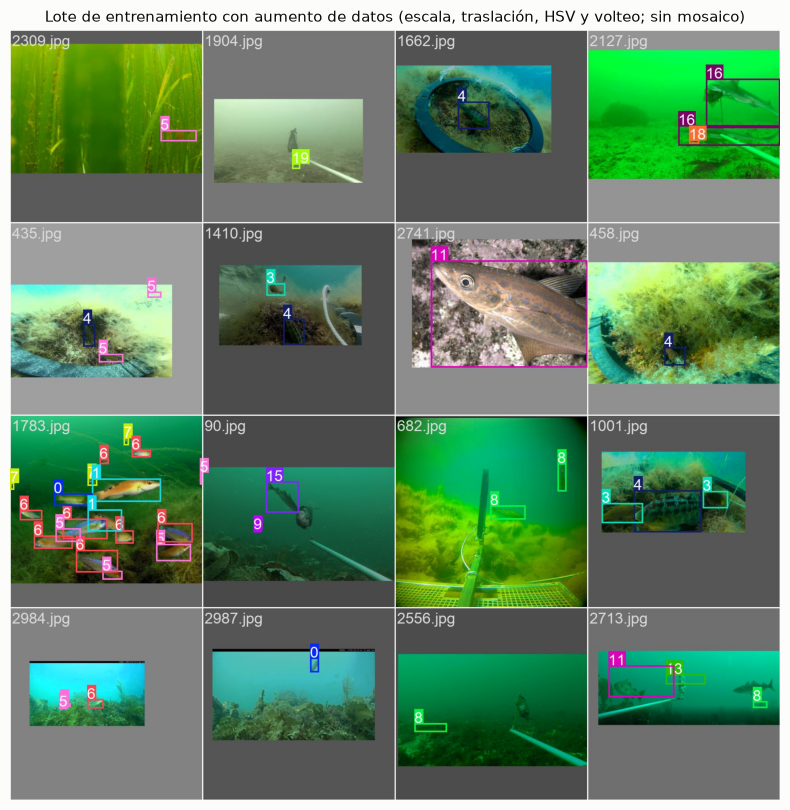

In [7]:
# Lote de entrenamiento tal como lo ve la red (letterbox + aumento de datos, sin mosaico)
ruta_lote = RUN_DIR / "train_batch0.jpg"
if ruta_lote.exists():
    plt.figure(figsize=(10, 10))
    plt.imshow(Image.open(ruta_lote))
    plt.title("Lote de entrenamiento con aumento de datos (escala, traslación, HSV y volteo; sin mosaico)")
    plt.axis("off")
    plt.show()

## 5. Curvas de entrenamiento

Pérdidas de entrenamiento y validación por época y métricas de validación. La línea discontinua marca la época de `best.pt`.

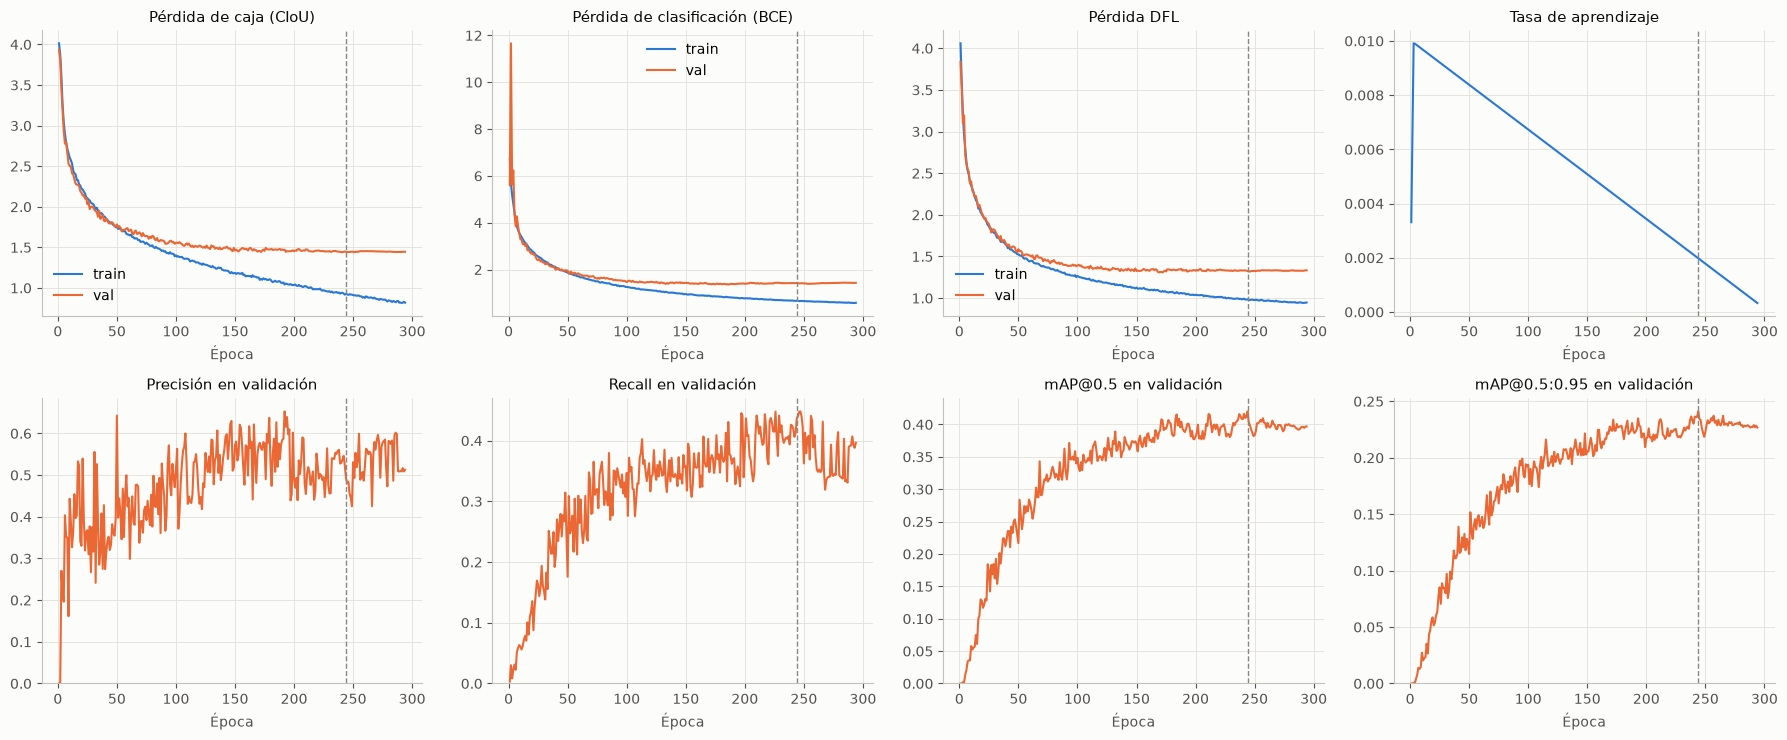

Épocas ejecutadas: 294 | mejor época: 244 | tiempo medio por época: 16.3 s


In [8]:
hist = pd.read_csv(RUN_DIR / "results.csv")
hist.columns = hist.columns.str.strip()
epocas_ejecutadas = int(hist.epoch.max())
mejor_epoca = int(hist.loc[hist["metrics/mAP50-95(B)"].idxmax(), "epoch"])
tiempo_por_epoca_s = float(hist.time.iloc[-1] / len(hist))

perdidas = [("box_loss", "Pérdida de caja (CIoU)"), ("cls_loss", "Pérdida de clasificación (BCE)"), ("dfl_loss", "Pérdida DFL")]
metricas = [("metrics/precision(B)", "Precisión"), ("metrics/recall(B)", "Recall"),
            ("metrics/mAP50(B)", "mAP@0.5"), ("metrics/mAP50-95(B)", "mAP@0.5:0.95")]

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, (clave, titulo) in zip(axes[0], perdidas):
    ax.plot(hist.epoch, hist[f"train/{clave}"], color=AZUL, lw=1.5, label="train")
    ax.plot(hist.epoch, hist[f"val/{clave}"], color=NARANJA, lw=1.5, label="val")
    ax.set_title(titulo)
    ax.legend()
axes[0, 3].plot(hist.epoch, hist["lr/pg0"], color=AZUL, lw=1.5)
axes[0, 3].set_title("Tasa de aprendizaje")
for ax, (clave, titulo) in zip(axes[1], metricas):
    ax.plot(hist.epoch, hist[clave], color=NARANJA, lw=1.5)
    ax.set_title(f"{titulo} en validación")
    ax.set_ylim(0, None)
for ax in axes.flat:
    ax.set_xlabel("Época")
    ax.axvline(mejor_epoca, color=GRIS, ls="--", lw=1)
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "curvas_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Épocas ejecutadas: {epocas_ejecutadas} | mejor época: {mejor_epoca} | tiempo medio por época: {tiempo_por_epoca_s:.1f} s")

## 6. Evaluación en validación y test (métricas de Ultralytics)

Se evalúa `best.pt` (elegido por mAP50-95 en validación) en val y, una sola vez, en test. Métricas de Ultralytics:

- **Precisión y recall** medios entre clases, al umbral de confianza que maximiza el F1 medio; **F1** = 2PR/(P+R).
- **mAP@0.5**, **mAP@0.75** y **mAP@0.5:0.95** (COCO): AP por clase promediado entre las clases con instancias en el conjunto evaluado.
- Para el mAP se usa `conf = 0.001` e IoU de NMS 0,5 (`IOU_NMS`), el protocolo común de esta variante; el valor estándar de Ultralytics es 0,7.

La comparación entre modelos no usa estas métricas, sino las del evaluador común de `comun.py` (sección 10), que calcula todo igual para todos los modelos.

In [9]:
mejor = YOLO(PESOS)
args_eval = dict(data=str(DATA_YAML), imgsz=HIPERPARAMETROS["imgsz"], batch=HIPERPARAMETROS["batch"],
                 conf=0.001, iou=IOU_NMS, device=DISPOSITIVO, project=str(DIR_RUNS), plots=True,
                 save_json=True)   # guarda las detecciones de la evaluación (sección 9)
met = {
    "val": mejor.val(split="val", name="evaluacion_val", **args_eval),
    "test": mejor.val(split="test", name="evaluacion_test", **args_eval),
}


def resumen_metricas(m):
    p, r = float(m.box.mp), float(m.box.mr)
    return {"precision": p, "recall": r, "F1": 2 * p * r / (p + r + 1e-16),
            "mAP50": float(m.box.map50), "mAP75": float(m.box.map75), "mAP50_95": float(m.box.map)}


tabla_global = pd.DataFrame({s: resumen_metricas(m) for s, m in met.items()}).T
tabla_global.to_csv(DIR_RESULTADOS / "metricas_val_test.csv")
tabla_global.round(4)

Ultralytics 8.4.192  Python-3.14.0 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)


YOLOv8n summary (fused): 72 layers, 3,011,108 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 852.3±127.9 MB/s, size: 225.9 KB)


val: Scanning C:\Users\rslat\OneDrive\Escritorio\TareaDL2\particion_80_10_10\datasets\fjordfish\labels\val.cache... 301 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 301/301 57.4Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/19 75.3s/it 22.6s<22:36

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 10% ━─────────── 2/19 1.4it/s 22.8s<12.3s

... (129 outputs left out)

 Average Recall     (AR) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.650


 Average Recall     (AR) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.384


Results saved to C:\Users\rslat\tarea2_runs_80_10_10\reales\yolo_desde_cero\evaluacion_test-2


,precision,recall,F1,mAP50,mAP75,mAP50_95
val,0.5164,0.4252,0.4664,0.4243,0.2327,0.2352
test,0.5614,0.4048,0.4704,0.4344,0.2265,0.2464


Métricas por clase en test, según Ultralytics.

In [10]:
# Métricas por clase en test (solo aparecen las clases con instancias en test)
por_clase = pd.DataFrame(met["test"].summary())
por_clase.to_csv(DIR_RESULTADOS / "metricas_por_clase_test.csv", index=False)
por_clase.sort_values("Instances", ascending=False).reset_index(drop=True)

,Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP75,mAP50-95
0,goldsinny,80,159,0.60455,0.49057,0.54163,0.44831,0.22335,0.23879
1,corkwing_male,115,117,0.85271,0.85470,0.85370,0.88859,0.63101,0.56788
2,cod,63,87,0.87519,0.80598,0.83916,0.85315,0.60296,0.55182
3,spiny_dogfish,33,51,0.82815,0.70588,0.76215,0.75163,0.44677,0.44870
4,corkwing_female,38,51,0.76327,0.50980,0.61130,0.60333,0.44148,0.41225
5,gadines_unknown,10,36,0.85040,0.31628,0.46108,0.57800,0.24128,0.28393
6,labrids_unknown,21,34,0.30787,0.14706,0.19904,0.15533,0.08010,0.07193
7,brown_crab,11,18,0.80042,0.22293,0.34873,0.38353,0.00131,0.09807
8,cod_yoy,12,14,0.41250,0.35714,0.38283,0.47000,0.15940,0.23370
9,pollack,12,13,0.39567,0.38462,0.39007,0.24345,0.16517,0.15138


El mismo AP50 por clase como gráfico, de menor a mayor, con el número de instancias de cada clase en test.

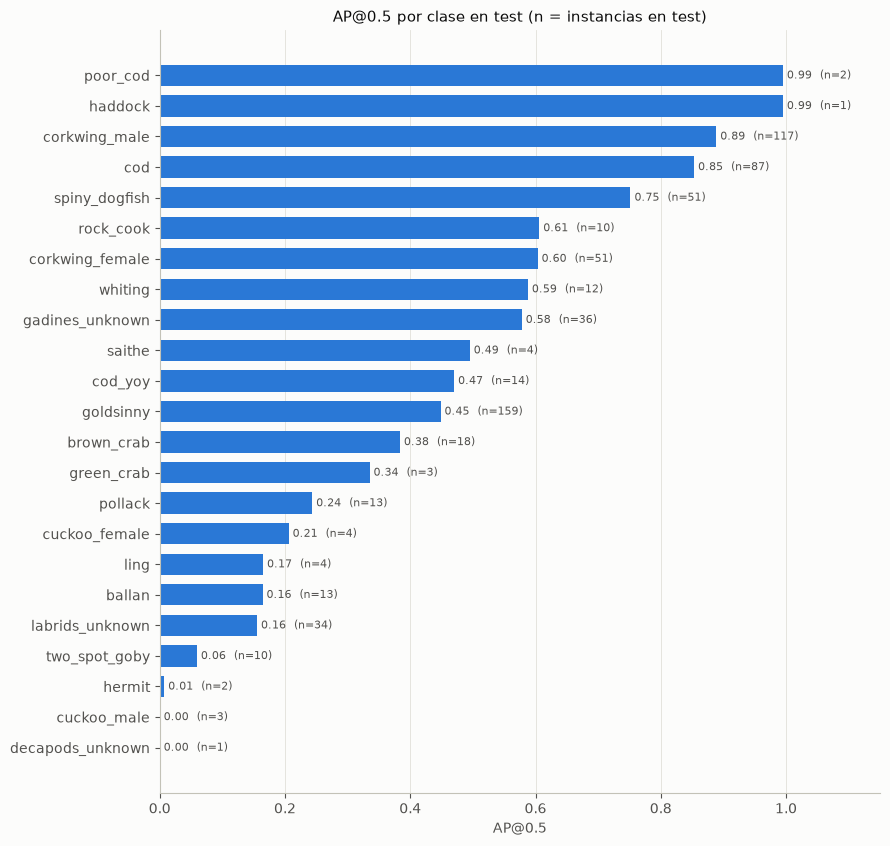

In [11]:
barras = por_clase.sort_values(["mAP50", "Instances"])
fig, ax = plt.subplots(figsize=(9, 0.32 * len(barras) + 1.2))
ax.barh(barras.Class, barras.mAP50, height=0.7, color=AZUL)
for yi, (v, n) in enumerate(zip(barras.mAP50, barras.Instances)):
    ax.text(v, yi, f" {v:.2f}  (n={n})", va="center", fontsize=8, color="#52514e")
ax.set_xlim(0, 1.15)
ax.set_xlabel("AP@0.5")
ax.set_title("AP@0.5 por clase en test (n = instancias en test)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "ap50_por_clase_test.png", dpi=150, bbox_inches="tight")
plt.show()

Matriz de confusión normalizada y curva precisión-recall que genera Ultralytics para test.

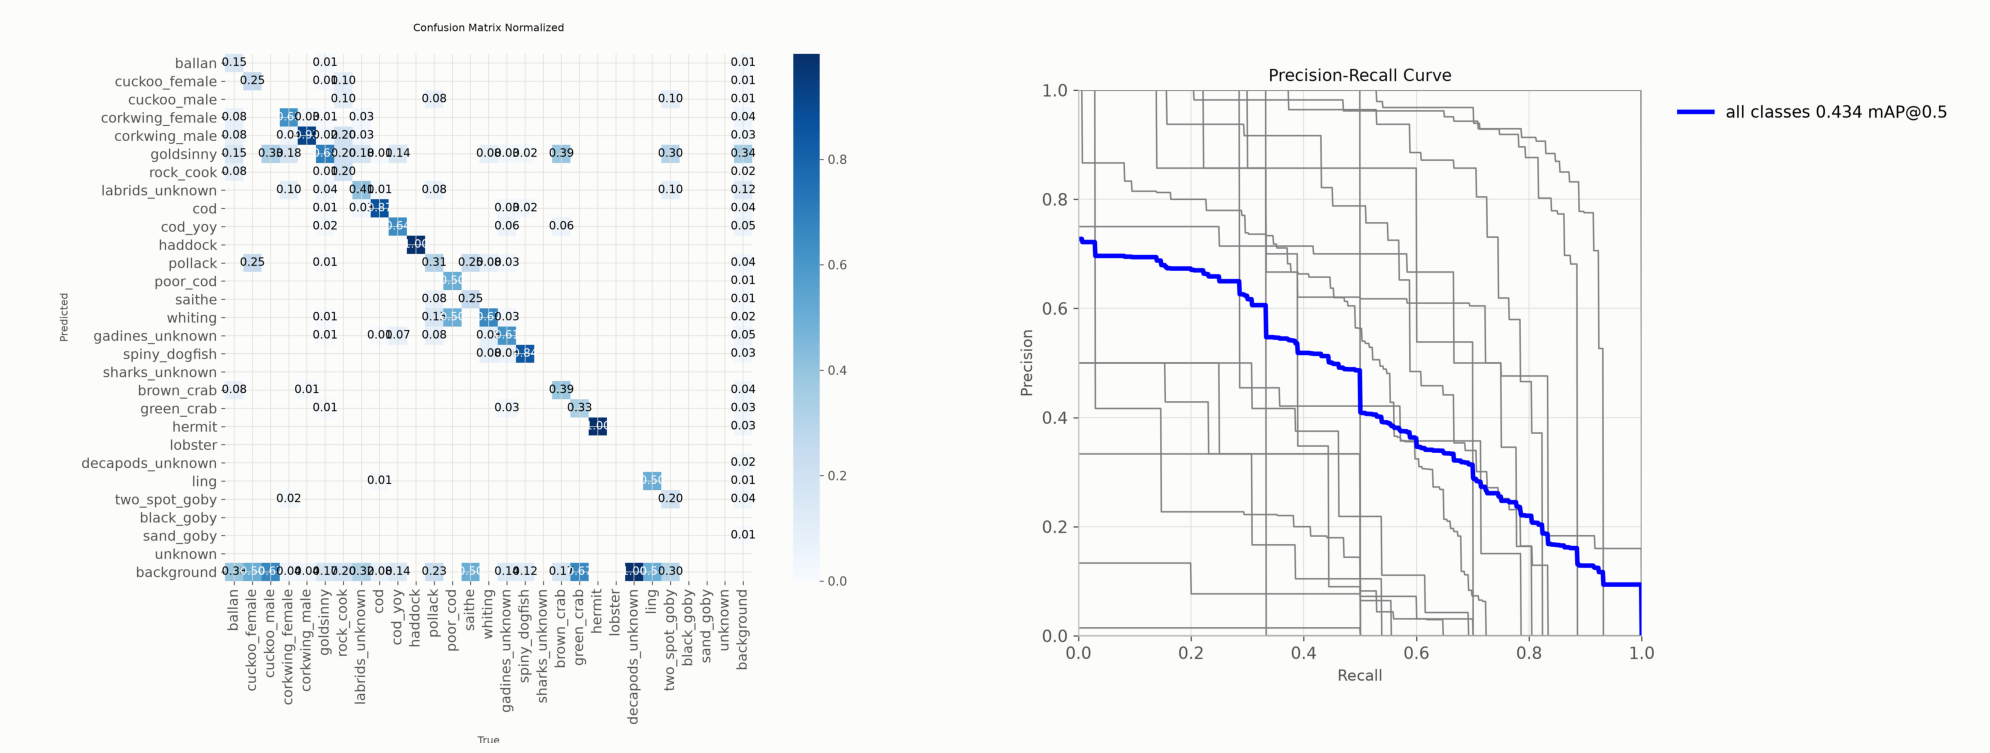

Gráficos de test en: C:\Users\rslat\tarea2_runs_80_10_10\reales\yolo_desde_cero\evaluacion_test-2


In [12]:
# Matriz de confusión normalizada y curva precisión-recall generadas por Ultralytics para test
dir_test = Path(met["test"].save_dir)
fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, archivo in zip(axes, ["confusion_matrix_normalized.png", "BoxPR_curve.png"]):
    ax.imshow(Image.open(dir_test / archivo))
    ax.axis("off")
fig.tight_layout()
plt.show()
print("Gráficos de test en:", dir_test)

## 7. Eficiencia: tamaño del modelo y velocidad de inferencia

Parámetros y GFLOPs (de la sección 3), tamaño del archivo de pesos y velocidad con **lote de 1 imagen** sobre imágenes de test, después de un calentamiento. La medición usa un lienzo de 640×640, igual que los otros modelos. El tiempo se separa en preprocesamiento, inferencia y postprocesamiento (NMS). Como referencia también se reporta el tiempo de inferencia por imagen al evaluar test en lotes (`ms_inferencia_en_lote`).

In [13]:
imgs_test = sorted((DATA_YAML.parent / datos["test"]).glob("*.jpg"))
args_pred = dict(imgsz=HIPERPARAMETROS["imgsz"], device=DISPOSITIVO, verbose=False, rect=False, conf=UMBRAL_CONFIANZA)   # lienzo de 640×640 y umbral común, igual que 01 y 04

for ruta in imgs_test[:10]:                       # calentamiento
    mejor.predict(ruta, **args_pred)
tiempos = pd.DataFrame([mejor.predict(ruta, **args_pred)[0].speed for ruta in imgs_test[:N_IMAGENES_VELOCIDAD]])
ms_total = float(tiempos.sum(axis=1).mean())

eficiencia = {
    "parametros_M": n_parametros / 1e6,
    "GFLOPs": gflops,
    "tamano_pesos_MB": PESOS.stat().st_size / 1e6,
    "ms_preproceso": float(tiempos.preprocess.mean()),
    "ms_inferencia": float(tiempos.inference.mean()),
    "ms_postproceso": float(tiempos.postprocess.mean()),
    "ms_total_por_imagen": ms_total,
    "FPS": 1000 / ms_total,
    "ms_inferencia_en_lote": float(met["test"].speed["inference"]),   # evaluación de test con lote = batch
}
pd.Series(eficiencia).round(3).to_frame("valor")

,valor
parametros_M,3.016
GFLOPs,8.221
tamano_pesos_MB,6.287
ms_preproceso,1.523
ms_inferencia,7.447
ms_postproceso,1.653
ms_total_por_imagen,10.623
FPS,94.137
ms_inferencia_en_lote,2.629


## 8. Resultados cualitativos

Imágenes de test elegidas al azar (semilla fija): anotación real a la izquierda y predicción a la derecha (confianza ≥ `UMBRAL_CONFIANZA`).

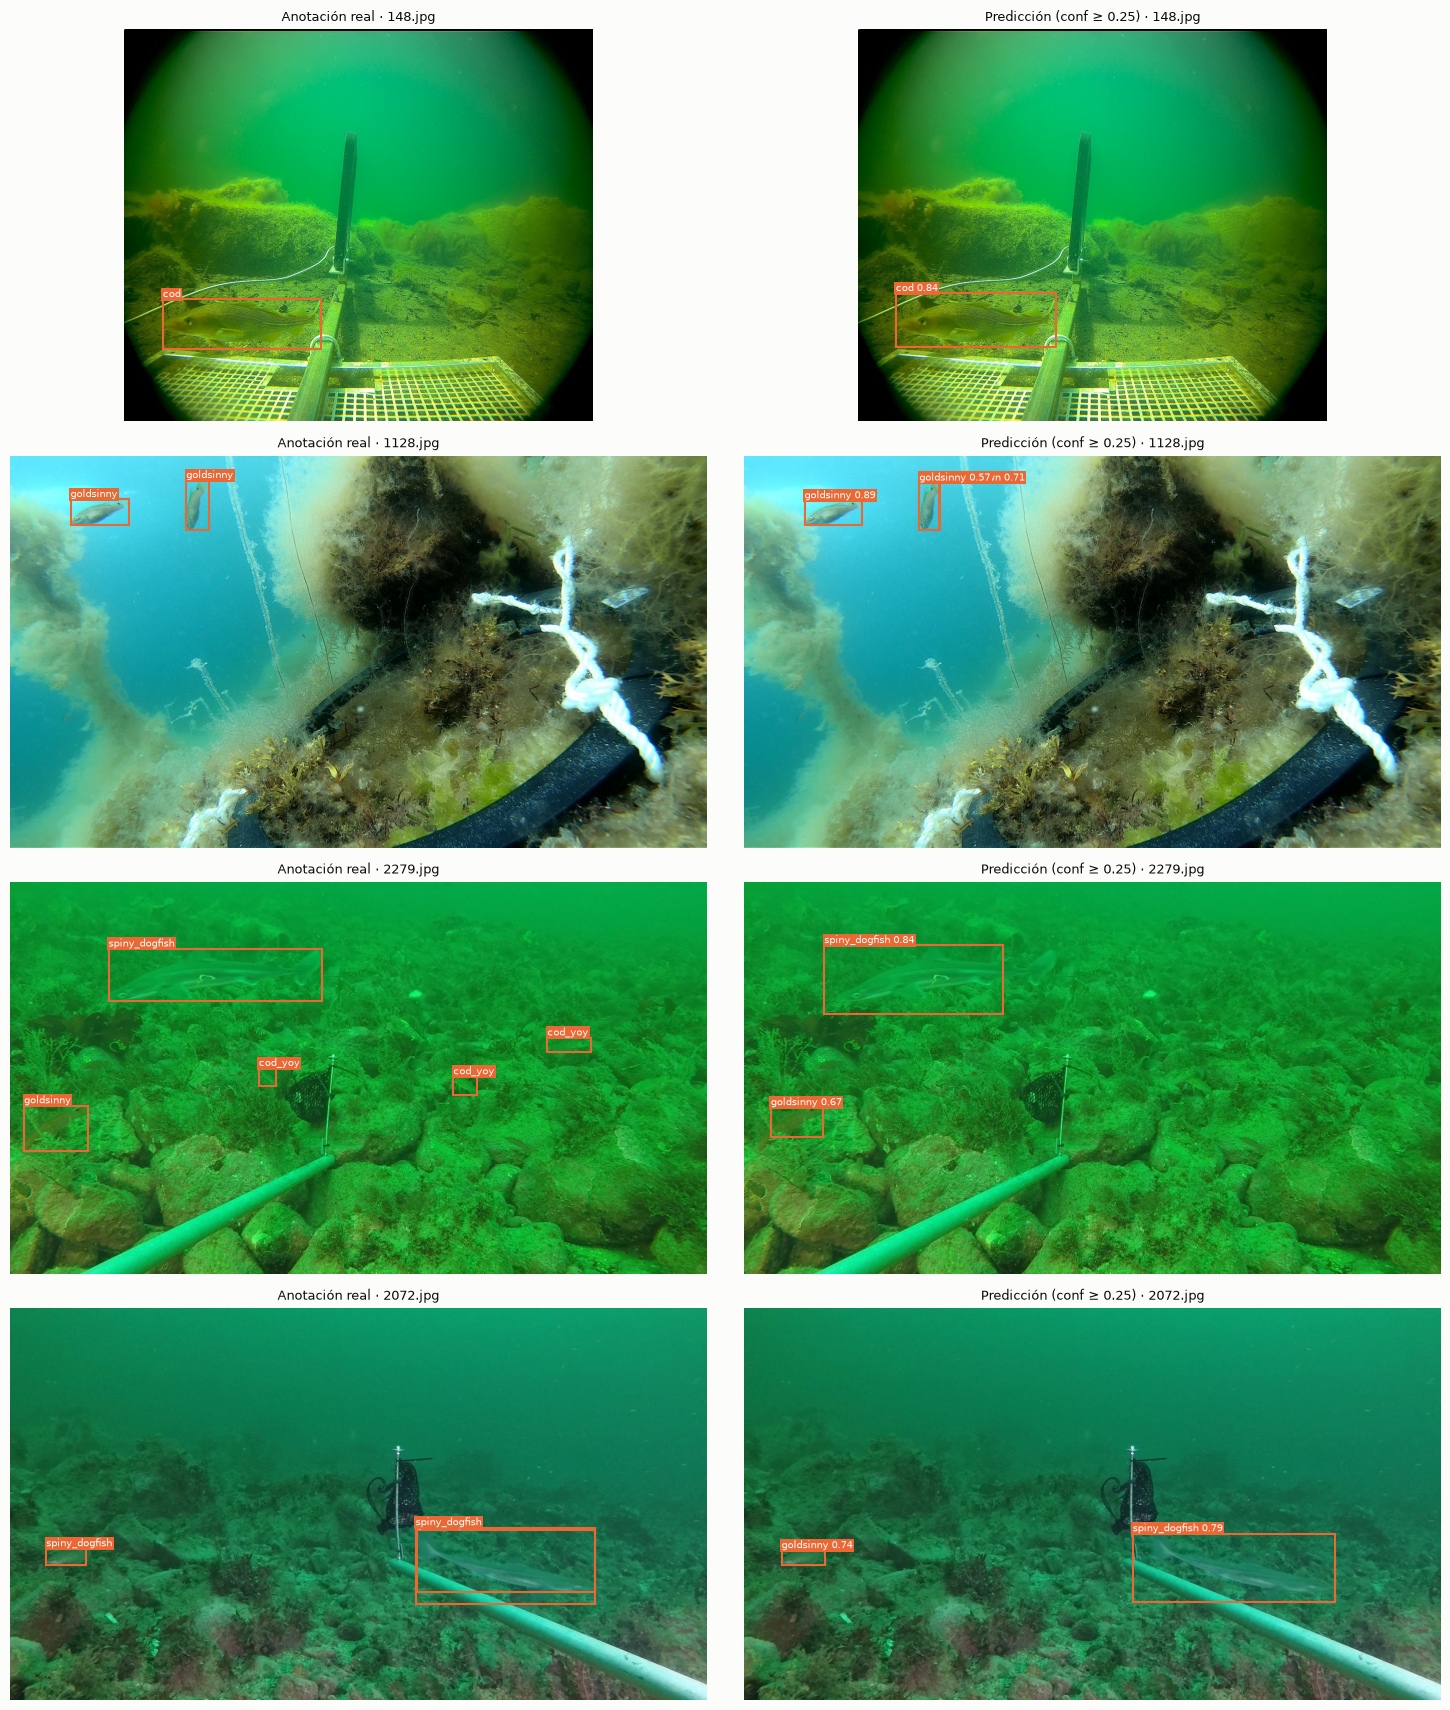

In [14]:


def dibujar(ax, img, cajas, titulo):
    ax.imshow(img)
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")
    for c, x1, y1, x2, y2, conf in cajas:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=NARANJA, lw=1.5))
        texto = NOMBRES[c] if conf is None else f"{NOMBRES[c]} {conf:.2f}"
        ax.text(x1, y1, texto, color="white", fontsize=7, va="top" if y1 < 0.05 * img.height else "bottom",
                bbox=dict(fc=NARANJA, ec="none", pad=1), clip_on=True)


ejemplos = random.Random(SEMILLA).sample(imgs_test, N_EJEMPLOS)
fig, axes = plt.subplots(N_EJEMPLOS, 2, figsize=(15, 4.3 * N_EJEMPLOS))
for (ax_gt, ax_pred), ruta in zip(axes, ejemplos):
    img = Image.open(ruta)
    W, H = img.size
    gt = np.loadtxt(DATA_YAML.parent / "labels" / "test" / f"{ruta.stem}.txt", ndmin=2)
    cajas_gt = [(int(c), (x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H, None) for c, x, y, w, h in gt]
    pred = mejor.predict(ruta, **args_pred)[0].boxes
    cajas_pred = [(int(c), *xyxy, conf) for c, xyxy, conf in zip(pred.cls.tolist(), pred.xyxy.tolist(), pred.conf.tolist())]
    dibujar(ax_gt, img, cajas_gt, f"Anotación real · {ruta.name}")
    dibujar(ax_pred, img, cajas_pred, f"Predicción (conf ≥ {UMBRAL_CONFIANZA}) · {ruta.name}")
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "ejemplos_test.png", dpi=120, bbox_inches="tight")
plt.show()

## 9. Predicciones de validación y test

Se guardan en `predicciones_val.csv` y `predicciones_test.csv` las mismas detecciones con que Ultralytics calculó el mAP de la sección 6: confianza ≥ 0,001, NMS **multietiqueta** con IoU 0,5 (una caja puede dar una detección por cada clase que supere el umbral) y hasta 300 por imagen, con coordenadas en píxeles de las imágenes de `datasets/fjordfish/images/<partición>`. La CNN propia y Faster R-CNN listan sus detecciones con este mismo protocolo, que cambia el mAP: con NMS de una sola etiqueta, como hace `predict`, el mismo modelo obtiene un mAP menor. Es el formato común de todos los modelos: con estos archivos el evaluador común calcula las métricas sin volver a ejecutar el modelo.

In [15]:
def predicciones_de_la_evaluacion(split):
    """Las detecciones que usó Ultralytics para su mAP en la sección 6, en el formato común (px de la imagen)."""
    archivo = Path(met[split].save_dir) / "predictions.json"
    detecciones = json.loads(archivo.read_text(encoding="utf-8")) if archivo.exists() else []   # sin detecciones no se escribe
    # Ultralytics guarda la caja como x, y (esquina superior izquierda), ancho y alto, y la clase sumándole 1
    filas = [(str(d["image_id"]), d["category_id"] - 1, d["score"], d["bbox"][0], d["bbox"][1],
              d["bbox"][0] + d["bbox"][2], d["bbox"][1] + d["bbox"][3]) for d in detecciones]
    return pd.DataFrame(filas, columns=["id", "clase_id", "confianza", "x1", "y1", "x2", "y2"])


predicciones = {}
for split in ("val", "test"):
    predicciones[split] = predicciones_de_la_evaluacion(split)
    predicciones[split].to_csv(DIR_RESULTADOS / f"predicciones_{split}.csv", index=False)
    print(f"{split}: {len(predicciones[split])} detecciones en {predicciones[split].id.nunique()} imágenes")

val: 5685 detecciones en 301 imágenes
test: 6592 detecciones en 301 imágenes


## 10. Métricas con el evaluador común

Se calculan el mAP50, el mAP75 y el mAP50-95 con el evaluador común de `comun.py` (el mismo que usa `05_comparacion.ipynb` para todos los modelos) a partir de las predicciones de la sección 9, que son exactamente las que usó Ultralytics, y se comparan con las de la sección 6. Así se comprueba que el evaluador común está bien: la diferencia debería ser de milésimas, porque ambos siguen la definición de COCO y solo difieren en detalles (Ultralytics empareja predicciones y cajas reales por IoU en vez de por confianza, e integra la curva precisión-recall con trapecios).

La precisión, el recall y el F1 con el umbral común (D8) se calculan en `05_comparacion.ipynb`, una vez que el grupo elija el umbral.

In [16]:
filas = []
for split in ("val", "test"):
    reales = cargar_cajas_reales(DIR_DATASET, split, particion[split])
    propio = evaluar_detecciones(predicciones[split], reales, nombres=NOMBRES)
    de_ultralytics = resumen_metricas(met[split])
    for metrica in ("mAP50", "mAP75", "mAP50_95"):
        filas.append({"partición": split, "métrica": metrica,
                      "evaluador común": propio[metrica], "Ultralytics": de_ultralytics[metrica]})
tabla_evaluadores = pd.DataFrame(filas)
tabla_evaluadores["diferencia"] = tabla_evaluadores["evaluador común"] - tabla_evaluadores["Ultralytics"]
tabla_evaluadores.to_csv(DIR_RESULTADOS / "evaluador_comun_vs_ultralytics.csv", index=False)
tabla_evaluadores.round(4)

,partición,métrica,evaluador común,Ultralytics,diferencia
0,val,mAP50,0.4265,0.4243,0.0022
1,val,mAP75,0.2360,0.2327,0.0033
2,val,mAP50_95,0.2379,0.2352,0.0027
3,test,mAP50,0.4358,0.4344,0.0014
4,test,mAP75,0.2293,0.2265,0.0027
5,test,mAP50_95,0.2483,0.2464,0.0019


## 11. Resumen para la comparación

Métricas que pide la tarea (precisión, mAP, tiempo de entrenamiento) y otras de eficiencia. Se guardan en `resultados/yolo_desde_cero/resumen.json` y `resumen.csv`, junto con `historial.csv` (pérdidas y mAP de validación por época, con las columnas comunes a todos los modelos). `05_comparacion.ipynb` une los archivos de todos los modelos.

Las métricas de este resumen son las de Ultralytics: la precisión y el recall están al umbral que maximiza el F1. Por eso `05_comparacion.ipynb` no las usa directamente, sino que recalcula todas las métricas de todos los modelos con el evaluador común y el umbral común (D8), a partir de las predicciones de la sección 9.

In [17]:
historial = pd.DataFrame({
    "epoca": hist.epoch,
    "tiempo_s": hist.time,                    # tiempo acumulado desde el inicio del entrenamiento
    "perdida_train": hist[["train/box_loss", "train/cls_loss", "train/dfl_loss"]].sum(axis=1),
    "perdida_val": hist[["val/box_loss", "val/cls_loss", "val/dfl_loss"]].sum(axis=1),
    "val_mAP50": hist["metrics/mAP50(B)"],
    "val_mAP50_95": hist["metrics/mAP50-95(B)"],
})
historial.to_csv(DIR_RESULTADOS / "historial.csv", index=False)

resumen = {
    "modelo": f"YOLO desde cero ({Path(MODELO_YAML).stem})",
    "huella_particion": huella,
    "epocas_ejecutadas": epocas_ejecutadas,
    "mejor_epoca": mejor_epoca,
    "tiempo_entrenamiento_min": info_entrenamiento["tiempo_entrenamiento_s"] / 60,
    "tiempo_por_epoca_s": tiempo_por_epoca_s,
    "memoria_gpu_max_GB": info_entrenamiento["memoria_gpu_max_GB"],
    **{f"test_{k}": v for k, v in resumen_metricas(met["test"]).items()},
    **{f"val_{k}": v for k, v in resumen_metricas(met["val"]).items()},
    **eficiencia,
}
(DIR_RESULTADOS / "resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
pd.Series(resumen).to_frame("valor").to_csv(DIR_RESULTADOS / "resumen.csv")
pd.Series(resumen).to_frame("valor")

,valor
modelo,YOLO desde cero (yolov8n)
huella_particion,84ea7ae5b688
epocas_ejecutadas,294
mejor_epoca,244
tiempo_entrenamiento_min,79.951667
tiempo_por_epoca_s,16.260102
memoria_gpu_max_GB,2.59
test_precision,0.561413
test_recall,0.404837
test_F1,0.470439


## 12. ✍️ Justificación de las decisiones (completar por el grupo)

> La tarea pide justificar estas decisiones con argumentos propios del grupo; el uso de IA generativa para diseñar la solución o analizar resultados está prohibido.

- **Arquitectura y escala** (`MODELO_YAML`):
- **Resolución de entrada y tamaño de lote**:
- **Optimizador y tasa de aprendizaje**:
- **Número de épocas y parada temprana**:
- **Regularización** (weight decay, aumento de datos, parada temprana, EMA de los pesos):
- **Aumento de datos**:
- **Desbalance de clases**:

## 13. ✍️ Análisis de resultados (completar por el grupo)

-

## ✍️ Declaración de uso de IA generativa

> Completar según lo que pide la tarea (herramienta y propósito específico).